In [2]:
# Cell 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Cell 2: Load cleaned dataset

df = pd.read_csv(
    "../data/processed/usgs_inventory_missing_cleaned.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (8981, 37)


,FireName,FireYear,FireIgnitionDate,FireState,AssessmentFireID,AssessmentSegmentID,UniqueObservationID,SiteName,ObservationDate,ObservationLatitude,...,1YearStormI30,1YearStormI60,RainfallRatio15,RainfallRatio30,RainfallRatio60,HM23,dNBR/1000,KF,UpstreamArea,PreviousUSGSInventory
0,Apple,2020,20200731,CA,aed2020,aed2020_7943,Apple_2020_0001,"""Dry Creek"" east of Little San Gorgonio Creek,...",20220819.0,34.052442,...,25.75,18.77,NaN,1.56,1.81,0.2670,0.2769,0.1200,1.2603,Graber (2023)
1,Apple,2020,20200731,CA,aed2020,aed2020_9918,Apple_2020_0002,Gilman Canyon (tributary to San Gorginio River...,20221129.0,34.031818,...,25.75,18.77,1.64,1.55,1.49,0.7365,0.5839,0.1279,7.5526,Graber (2023)
2,Bear,2021,20210608,UT,ber2021,ber2021_538,Bear_2021_0001,"US Hwy 6, MP 226.7, Crandall Canyon",20230903.0,39.763579,...,17.34,10.73,2.51,2.84,2.32,0.3714,0.4991,0.2720,10.8958,Graber (2024)
3,Blaisdell,2005,20050826,CA,bla,bla_122,Blaisdell_2005_0001,NaN,NaN,33.888020,...,15.49,11.20,0.34,0.39,0.48,0.0217,0.0695,0.0554,3.5557,Staley and others (2016)
4,Blaisdell,2005,20050826,CA,bla,bla_122,Blaisdell_2005_0002,NaN,NaN,33.888020,...,15.49,11.20,0.44,0.49,0.36,0.0217,0.0695,0.0554,3.5557,Staley and others (2016)


In [4]:
# Cell 3: Define target and grouping variable

target = "Response"
group_column = "FireName"

y = df[target].copy()
groups = df[group_column].copy()

# Candidate 1: Logistic Regression - Reduced Features

reduced_features = [
    "StormAccumulation",
    "StormDuration",
    "PeakI60",
    "RainfallRatio60",
    "HM23",
    "dNBR/1000",
    "KF",
    "UpstreamArea",
    "DaysSinceFire",
    "YearAfterFire"
]

# Candidate 2: SVM - Full Features

full_features = [
    "StormAccumulation",
    "StormDuration",
    "PeakI15",
    "PeakI30",
    "PeakI60",
    "1YearStormI15",
    "1YearStormI30",
    "1YearStormI60",
    "RainfallRatio15",
    "RainfallRatio30",
    "RainfallRatio60",
    "HM23",
    "dNBR/1000",
    "KF",
    "UpstreamArea",
    "DaysSinceFire",
    "YearAfterFire"
]

print("Target:", target)
print("Wildfire groups:", groups.nunique())
print("Positive observations:", int(y.sum()))
print("Negative observations:", int((y == 0).sum()))

Target: Response
Wildfire groups: 80
Positive observations: 1140
Negative observations: 7841


In [5]:
# Cell 4: Define selected candidate models

models = {
    "Logistic Regression - Reduced": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            random_state=42
        ))
    ]),

    "SVM - Full": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            class_weight="balanced",
            probability=True,
            random_state=42
        ))
    ])
}

feature_sets = {
    "Logistic Regression - Reduced": reduced_features,
    "SVM - Full": full_features
}

print("Candidate models defined successfully!")

Candidate models defined successfully!


In [6]:
# Cell 5: Define wildfire-grouped cross-validation

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Validation strategy:", cv)
print("Grouping variable:", group_column)

Validation strategy: StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True)
Grouping variable: FireName


In [7]:
# Cell 6: Generate out-of-fold predictions

oof_results = {}

for model_name, model in models.items():

    X_current = df[feature_sets[model_name]].copy()

    oof_probabilities = np.zeros(len(df))
    oof_predictions = np.zeros(len(df), dtype=int)

    for fold, (train_idx, test_idx) in enumerate(
        cv.split(X_current, y, groups), start=1
    ):

        X_train = X_current.iloc[train_idx]
        X_test = X_current.iloc[test_idx]

        y_train = y.iloc[train_idx]

        model.fit(X_train, y_train)

        probabilities = model.predict_proba(X_test)[:, 1]

        predictions = (probabilities >= 0.5).astype(int)

        oof_probabilities[test_idx] = probabilities
        oof_predictions[test_idx] = predictions

        print(
            f"{model_name} | Fold {fold} completed"
        )

    oof_results[model_name] = {
        "probabilities": oof_probabilities,
        "predictions": oof_predictions
    }

print("\nOut-of-fold predictions generated successfully!")

Logistic Regression - Reduced | Fold 1 completed
Logistic Regression - Reduced | Fold 2 completed
Logistic Regression - Reduced | Fold 3 completed
Logistic Regression - Reduced | Fold 4 completed
Logistic Regression - Reduced | Fold 5 completed
SVM - Full | Fold 1 completed
SVM - Full | Fold 2 completed
SVM - Full | Fold 3 completed
SVM - Full | Fold 4 completed
SVM - Full | Fold 5 completed

Out-of-fold predictions generated successfully!


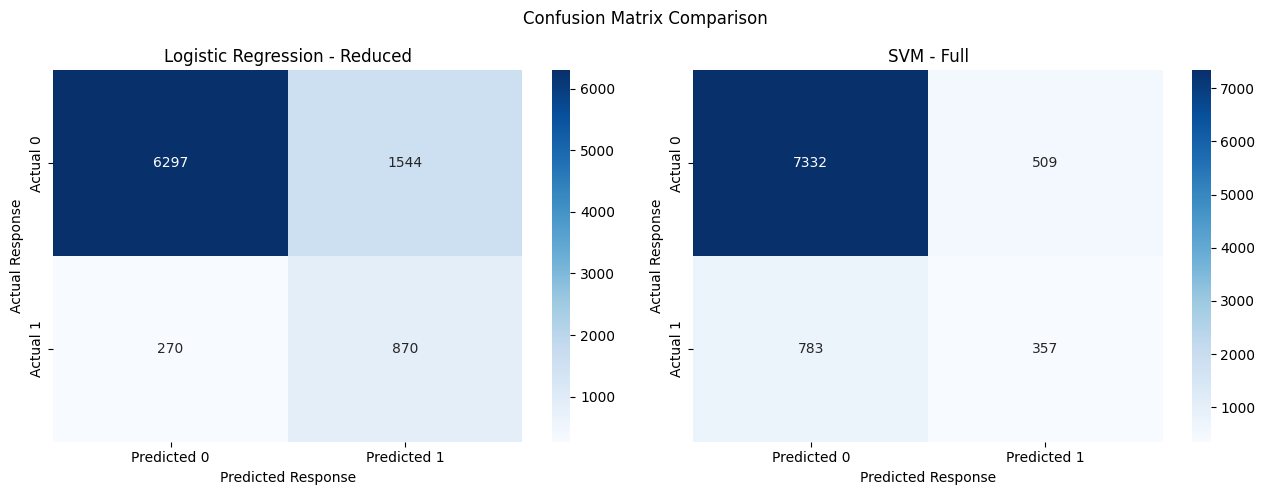

In [8]:
# Cell 7: Confusion Matrix Comparison

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (model_name, result) in zip(
    axes, oof_results.items()
):

    cm = confusion_matrix(
        y,
        result["predictions"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Response")
    ax.set_ylabel("Actual Response")

plt.suptitle("Confusion Matrix Comparison")
plt.tight_layout()
plt.show()

In [9]:
# Cell 8: Extract confusion matrix values

for model_name, result in oof_results.items():

    tn, fp, fn, tp = confusion_matrix(
        y,
        result["predictions"]
    ).ravel()

    print("\nModel:", model_name)

    print("True Negatives:", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("True Positives:", tp)


Model: Logistic Regression - Reduced
True Negatives: 6297
False Positives: 1544
False Negatives: 270
True Positives: 870

Model: SVM - Full
True Negatives: 7332
False Positives: 509
False Negatives: 783
True Positives: 357


In [10]:
# Cell 9: Classification Reports

for model_name, result in oof_results.items():

    print("\n" + "=" * 60)
    print("MODEL:", model_name)
    print("=" * 60)

    print(
        classification_report(
            y,
            result["predictions"],
            target_names=[
                "No Debris Flow (0)",
                "Debris Flow (1)"
            ],
            digits=4
        )
    )


MODEL: Logistic Regression - Reduced
                    precision    recall  f1-score   support

No Debris Flow (0)     0.9589    0.8031    0.8741      7841
   Debris Flow (1)     0.3604    0.7632    0.4896      1140

          accuracy                         0.7980      8981
         macro avg     0.6596    0.7831    0.6818      8981
      weighted avg     0.8829    0.7980    0.8253      8981


MODEL: SVM - Full
                    precision    recall  f1-score   support

No Debris Flow (0)     0.9035    0.9351    0.9190      7841
   Debris Flow (1)     0.4122    0.3132    0.3559      1140

          accuracy                         0.8561      8981
         macro avg     0.6579    0.6241    0.6375      8981
      weighted avg     0.8412    0.8561    0.8476      8981



In [11]:
# Cell 10: ROC-AUC and PR-AUC comparison

evaluation_results = []

for model_name, result in oof_results.items():

    probabilities = result["probabilities"]
    predictions = result["predictions"]

    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions),
        "Recall": recall_score(y, predictions),
        "F1_Score": f1_score(y, predictions),
        "ROC_AUC": roc_auc_score(y, probabilities),
        "PR_AUC": average_precision_score(y, probabilities)
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("Out-of-fold Model Evaluation:")
display(
    evaluation_df.round(4).sort_values(
        by="PR_AUC",
        ascending=False
    )
)

Out-of-fold Model Evaluation:


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Logistic Regression - Reduced,0.7980,0.3604,0.7632,0.4896,0.8443,0.4281
1,SVM - Full,0.8561,0.4122,0.3132,0.3559,0.8369,0.3954


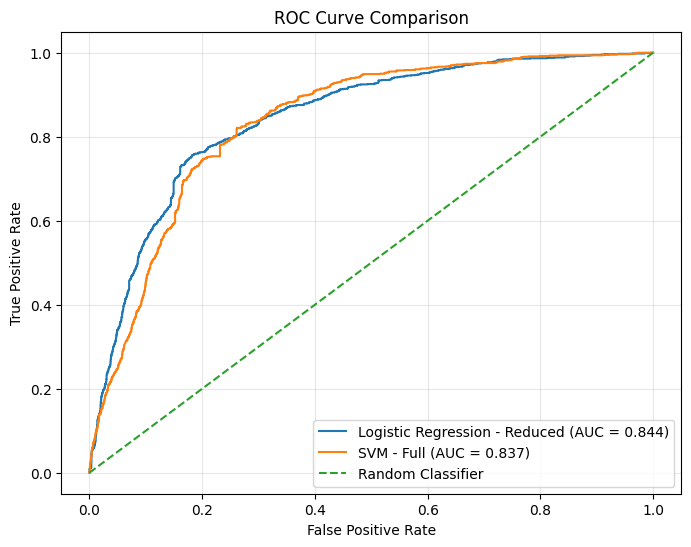

In [12]:
# Cell 11: ROC Curve Comparison

plt.figure(figsize=(8, 6))

for model_name, result in oof_results.items():

    fpr, tpr, thresholds = roc_curve(
        y,
        result["probabilities"]
    )

    auc_value = roc_auc_score(
        y,
        result["probabilities"]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

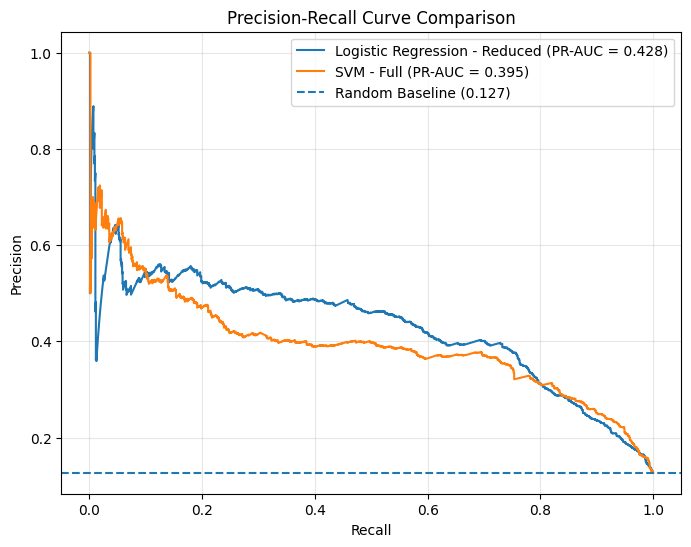

In [13]:
# Cell 12: Precision-Recall Curve Comparison

plt.figure(figsize=(8, 6))

for model_name, result in oof_results.items():

    precision, recall, thresholds = precision_recall_curve(
        y,
        result["probabilities"]
    )

    pr_auc = average_precision_score(
        y,
        result["probabilities"]
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (PR-AUC = {pr_auc:.3f})"
    )

baseline = y.mean()

plt.axhline(
    baseline,
    linestyle="--",
    label=f"Random Baseline ({baseline:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [14]:
# Cell 13: Investigate SVM prediction discrepancy

svm_model = models["SVM - Full"]
X_svm = df[full_features].copy()

oof_decision_scores = np.zeros(len(df))
oof_default_predictions = np.zeros(len(df), dtype=int)

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X_svm, y, groups), start=1
):

    X_train = X_svm.iloc[train_idx]
    X_test = X_svm.iloc[test_idx]
    y_train = y.iloc[train_idx]

    svm_model.fit(X_train, y_train)

    # Default SVM predictions
    default_predictions = svm_model.predict(X_test)

    # Raw decision scores
    decision_scores = svm_model.decision_function(X_test)

    oof_default_predictions[test_idx] = default_predictions
    oof_decision_scores[test_idx] = decision_scores

    print(f"Fold {fold} completed")

# Compare the two prediction methods
probability_predictions = oof_results[
    "SVM - Full"
]["predictions"]

print("\nSVM Prediction Method Comparison")

comparison = pd.DataFrame({
    "Method": [
        "Probability >= 0.5",
        "Default SVM predict()",
        "Decision score >= 0"
    ],
    "Precision": [
        precision_score(y, probability_predictions),
        precision_score(y, oof_default_predictions),
        precision_score(y, (oof_decision_scores >= 0).astype(int))
    ],
    "Recall": [
        recall_score(y, probability_predictions),
        recall_score(y, oof_default_predictions),
        recall_score(y, (oof_decision_scores >= 0).astype(int))
    ],
    "F1_Score": [
        f1_score(y, probability_predictions),
        f1_score(y, oof_default_predictions),
        f1_score(y, (oof_decision_scores >= 0).astype(int))
    ]
})

display(comparison.round(4))

Fold 1 completed
Fold 2 completed
Fold 3 completed
Fold 4 completed
Fold 5 completed

SVM Prediction Method Comparison


,Method,Precision,Recall,F1_Score
0,Probability >= 0.5,0.4122,0.3132,0.3559
1,Default SVM predict(),0.3654,0.7737,0.4963
2,Decision score >= 0,0.3654,0.7737,0.4963


In [15]:
# Cell 14: Corrected Out-of-Fold Evaluation

# Replace SVM's probability-threshold predictions
# with its default decision-boundary predictions.
oof_results["SVM - Full"]["predictions"] = oof_default_predictions

corrected_results = []

for model_name, result in oof_results.items():

    predictions = result["predictions"]
    probabilities = result["probabilities"]

    corrected_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions),
        "Recall": recall_score(y, predictions),
        "F1_Score": f1_score(y, predictions),
        "ROC_AUC": roc_auc_score(y, probabilities),
        "PR_AUC": average_precision_score(y, probabilities)
    })

corrected_df = pd.DataFrame(corrected_results)

display(corrected_df.round(4))

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,Logistic Regression - Reduced,0.7980,0.3604,0.7632,0.4896,0.8443,0.4281
1,SVM - Full,0.8007,0.3654,0.7737,0.4963,0.8369,0.3954


In [16]:
# Cell 15: Logistic Regression Threshold Analysis

lr_probabilities = oof_results[
    "Logistic Regression - Reduced"
]["probabilities"]

thresholds = [
    0.20, 0.25, 0.30, 0.35,
    0.40, 0.45, 0.50, 0.55,
    0.60, 0.65, 0.70
]

threshold_results = []

for threshold in thresholds:

    predictions = (
        lr_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y, predictions),
        "Recall": recall_score(y, predictions),
        "F1_Score": f1_score(y, predictions),
        "False_Positives": confusion_matrix(
            y, predictions
        )[0, 1],
        "False_Negatives": confusion_matrix(
            y, predictions
        )[1, 0]
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1_Score,False_Positives,False_Negatives
0,0.20,0.2123,0.9254,0.3454,3914,85
1,0.25,0.2359,0.8982,0.3737,3317,116
2,0.30,0.2594,0.8737,0.4000,2844,144
3,0.35,0.2830,0.8439,0.4239,2437,178
4,0.40,0.3050,0.8079,0.4428,2099,219
5,0.45,0.3345,0.7825,0.4686,1775,248
6,0.50,0.3604,0.7632,0.4896,1544,270
7,0.55,0.3845,0.7421,0.5066,1354,294
8,0.60,0.4022,0.6947,0.5095,1177,348
9,0.65,0.4073,0.6105,0.4886,1013,444


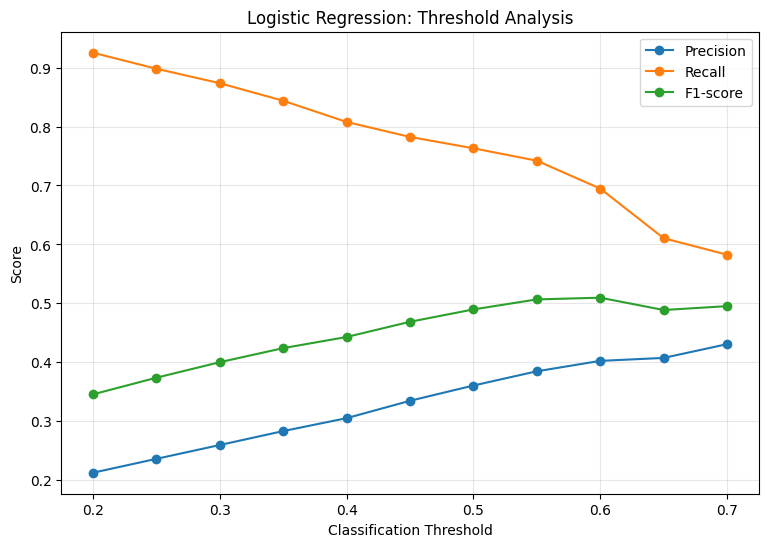

In [17]:
# Cell 16: Threshold vs Precision, Recall and F1

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1_Score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Logistic Regression: Threshold Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

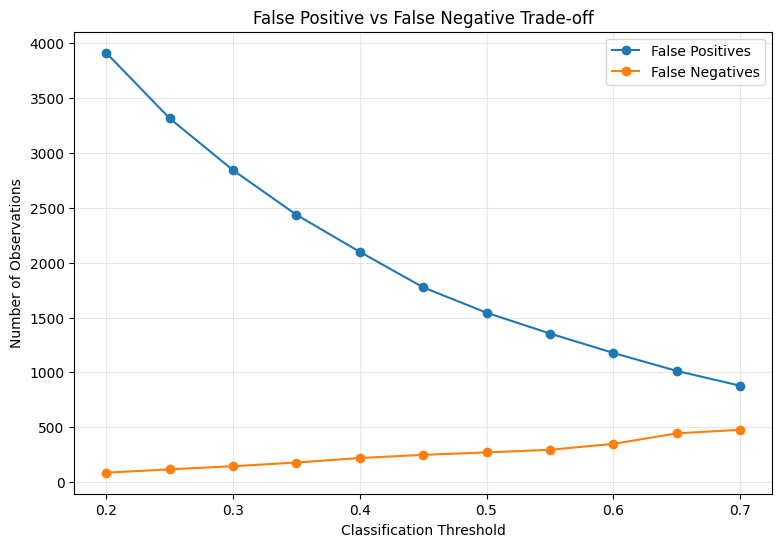

In [18]:
# Cell 17: False Positive and False Negative Analysis

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["False_Positives"],
    marker="o",
    label="False Positives"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["False_Negatives"],
    marker="o",
    label="False Negatives"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Number of Observations")
plt.title("False Positive vs False Negative Trade-off")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [19]:
# Cell 18: SVM Threshold Analysis

svm_probabilities = oof_results[
    "SVM - Full"
]["probabilities"]

thresholds = [
    0.20, 0.25, 0.30, 0.35,
    0.40, 0.45, 0.50, 0.55,
    0.60, 0.65, 0.70
]

svm_threshold_results = []

for threshold in thresholds:

    predictions = (
        svm_probabilities >= threshold
    ).astype(int)

    cm = confusion_matrix(y, predictions)

    svm_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y, predictions),
        "Recall": recall_score(y, predictions),
        "F1_Score": f1_score(y, predictions),
        "False_Positives": cm[0, 1],
        "False_Negatives": cm[1, 0]
    })

svm_threshold_df = pd.DataFrame(
    svm_threshold_results
)

display(svm_threshold_df.round(4))

,Threshold,Precision,Recall,F1_Score,False_Positives,False_Negatives
0,0.20,0.3707,0.6237,0.4650,1207,429
1,0.25,0.3853,0.5570,0.4555,1013,505
2,0.30,0.3955,0.5061,0.4440,882,563
3,0.35,0.3911,0.4316,0.4103,766,648
4,0.40,0.3966,0.3851,0.3907,668,701
5,0.45,0.4014,0.3535,0.3759,601,737
6,0.50,0.4122,0.3132,0.3559,509,783
7,0.55,0.4188,0.2579,0.3192,408,846
8,0.60,0.4510,0.2263,0.3014,314,882
9,0.65,0.4862,0.1851,0.2681,223,929


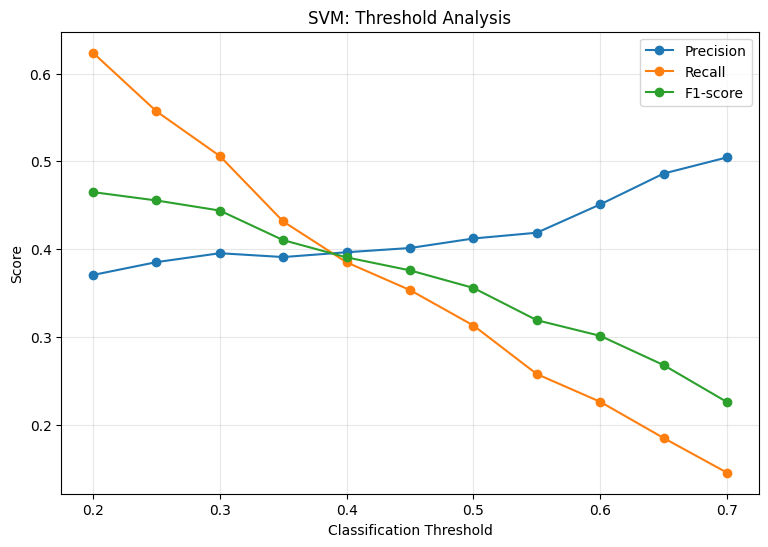

In [20]:
# Cell 19: SVM Threshold Performance

plt.figure(figsize=(9, 6))

plt.plot(
    svm_threshold_df["Threshold"],
    svm_threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    svm_threshold_df["Threshold"],
    svm_threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    svm_threshold_df["Threshold"],
    svm_threshold_df["F1_Score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("SVM: Threshold Analysis")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

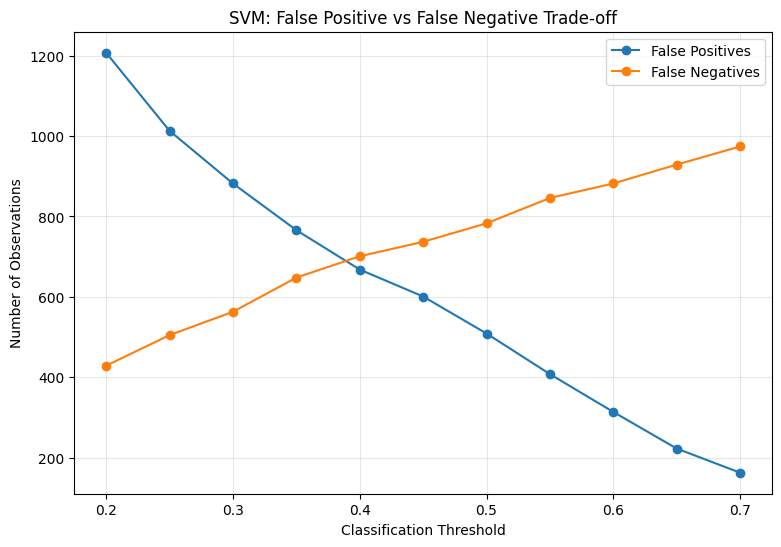

In [21]:
# Cell 20: SVM False Positive vs False Negative

plt.figure(figsize=(9, 6))

plt.plot(
    svm_threshold_df["Threshold"],
    svm_threshold_df["False_Positives"],
    marker="o",
    label="False Positives"
)

plt.plot(
    svm_threshold_df["Threshold"],
    svm_threshold_df["False_Negatives"],
    marker="o",
    label="False Negatives"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Number of Observations")
plt.title("SVM: False Positive vs False Negative Trade-off")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [22]:
# Cell 21: Fine-grained threshold optimisation

probability_models = {
    "Logistic Regression - Reduced":
        oof_results["Logistic Regression - Reduced"]["probabilities"],

    "SVM - Full":
        oof_results["SVM - Full"]["probabilities"]
}

fine_thresholds = np.arange(0.05, 0.951, 0.01)

fine_results = []

for model_name, probabilities in probability_models.items():

    for threshold in fine_thresholds:

        predictions = (probabilities >= threshold).astype(int)

        cm = confusion_matrix(y, predictions)

        fine_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(y, predictions, zero_division=0),
            "Recall": recall_score(y, predictions, zero_division=0),
            "F1_Score": f1_score(y, predictions, zero_division=0),
            "False_Positives": cm[0, 1],
            "False_Negatives": cm[1, 0]
        })

fine_threshold_df = pd.DataFrame(fine_results)

best_thresholds = (
    fine_threshold_df
    .loc[fine_threshold_df.groupby("Model")["F1_Score"].idxmax()]
    .reset_index(drop=True)
)

display(best_thresholds.round(4))

,Model,Threshold,Precision,Recall,F1_Score,False_Positives,False_Negatives
0,Logistic Regression - Reduced,0.57,0.3946,0.7325,0.5129,1281,305
1,SVM - Full,0.16,0.3661,0.7211,0.4857,1423,318


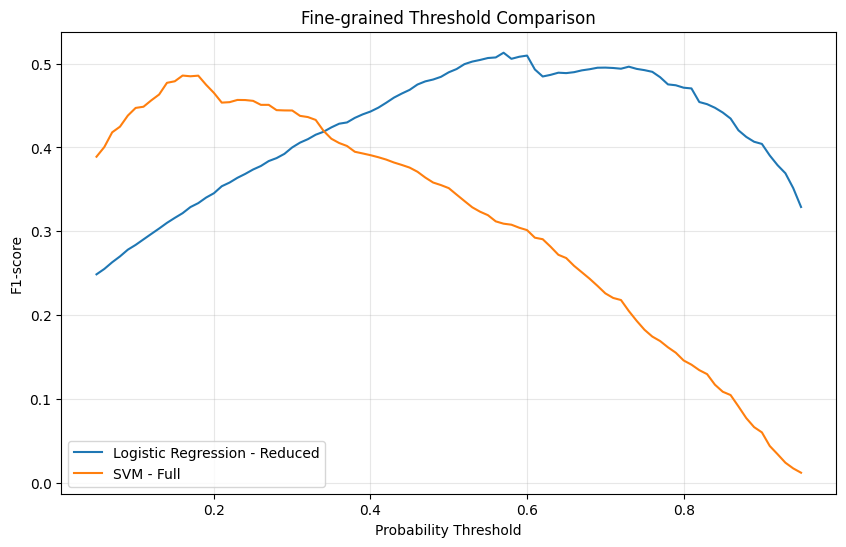

In [23]:
# Cell 22: Fine-grained F1-score comparison

plt.figure(figsize=(10, 6))

for model_name in fine_threshold_df["Model"].unique():

    subset = fine_threshold_df[
        fine_threshold_df["Model"] == model_name
    ]

    plt.plot(
        subset["Threshold"],
        subset["F1_Score"],
        label=model_name
    )

plt.xlabel("Probability Threshold")
plt.ylabel("F1-score")
plt.title("Fine-grained Threshold Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [24]:
# Cell 23: Display the best threshold for each model

for _, row in best_thresholds.iterrows():

    print("\nModel:", row["Model"])
    print("Best threshold:", round(row["Threshold"], 2))
    print("Precision:", round(row["Precision"], 4))
    print("Recall:", round(row["Recall"], 4))
    print("F1-score:", round(row["F1_Score"], 4))
    print("False positives:", row["False_Positives"])
    print("False negatives:", row["False_Negatives"])


Model: Logistic Regression - Reduced
Best threshold: 0.57
Precision: 0.3946
Recall: 0.7325
F1-score: 0.5129
False positives: 1281
False negatives: 305

Model: SVM - Full
Best threshold: 0.16
Precision: 0.3661
Recall: 0.7211
F1-score: 0.4857
False positives: 1423
False negatives: 318


In [25]:
# Cell 24: Create wildfire-group holdout

from sklearn.model_selection import StratifiedGroupKFold

# Create a new grouped split
holdout_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

# First fold becomes the holdout
train_idx, test_idx = next(
    holdout_cv.split(df, y, groups)
)

# Separate development and holdout data
X_dev = df.iloc[train_idx].copy()
X_test = df.iloc[test_idx].copy()

y_dev = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_dev = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

print("Development dataset shape:", X_dev.shape)
print("Holdout dataset shape:", X_test.shape)

print("\nDevelopment wildfire groups:",
      groups_dev.nunique())

print("Holdout wildfire groups:",
      groups_test.nunique())

print("\nDevelopment positive observations:",
      y_dev.sum())

print("Development negative observations:",
      (y_dev == 0).sum())

print("\nHoldout positive observations:",
      y_test.sum())

print("Holdout negative observations:",
      (y_test == 0).sum())

# Verify there is no wildfire overlap
overlap = set(groups_dev.unique()) & set(groups_test.unique())

print("\nOverlapping wildfire groups:", len(overlap))

assert len(overlap) == 0
assert y_test.nunique() == 2

print("\nWildfire-group holdout created successfully!")

Development dataset shape: (6241, 37)
Holdout dataset shape: (2740, 37)

Development wildfire groups: 69
Holdout wildfire groups: 11

Development positive observations: 922
Development negative observations: 5319

Holdout positive observations: 218
Holdout negative observations: 2522

Overlapping wildfire groups: 0

Wildfire-group holdout created successfully!


In [26]:
# Cell 25: Development-only grouped cross-validation

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Define candidate models
development_models = {
    "Logistic Regression - Reduced": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=3000,
            random_state=42
        ))
    ]),

    "SVM - Full": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            class_weight="balanced",
            probability=True,
            random_state=42
        ))
    ])
}

# Feature selection
development_features = {
    "Logistic Regression - Reduced": reduced_features,
    "SVM - Full": full_features
}

# Five-fold grouped cross-validation
development_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

development_oof = {}

for model_name, model in development_models.items():

    X_current = X_dev[
        development_features[model_name]
    ].copy()

    probabilities = np.zeros(len(X_dev))
    predictions = np.zeros(len(X_dev), dtype=int)

    for fold, (train_idx, valid_idx) in enumerate(
        development_cv.split(
            X_current,
            y_dev,
            groups_dev
        ),
        start=1
    ):

        X_train = X_current.iloc[train_idx]
        X_valid = X_current.iloc[valid_idx]

        y_train = y_dev.iloc[train_idx]

        model.fit(X_train, y_train)

        fold_probabilities = model.predict_proba(
            X_valid
        )[:, 1]

        fold_predictions = model.predict(X_valid)

        probabilities[valid_idx] = fold_probabilities
        predictions[valid_idx] = fold_predictions

        print(f"{model_name} | Fold {fold} completed")

    development_oof[model_name] = {
        "probabilities": probabilities,
        "predictions": predictions
    }

print("\nDevelopment-only OOF predictions generated!")

Logistic Regression - Reduced | Fold 1 completed
Logistic Regression - Reduced | Fold 2 completed
Logistic Regression - Reduced | Fold 3 completed
Logistic Regression - Reduced | Fold 4 completed
Logistic Regression - Reduced | Fold 5 completed
SVM - Full | Fold 1 completed
SVM - Full | Fold 2 completed
SVM - Full | Fold 3 completed
SVM - Full | Fold 4 completed
SVM - Full | Fold 5 completed

Development-only OOF predictions generated!


In [27]:
# Cell 26: Development-only threshold optimisation

development_threshold_results = []

thresholds = np.arange(0.05, 0.951, 0.01)

for model_name, result in development_oof.items():

    probabilities = result["probabilities"]

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        cm = confusion_matrix(y_dev, predictions)

        development_threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_dev, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_dev, predictions, zero_division=0
            ),
            "F1_Score": f1_score(
                y_dev, predictions, zero_division=0
            ),
            "False_Positives": cm[0, 1],
            "False_Negatives": cm[1, 0]
        })

development_threshold_df = pd.DataFrame(
    development_threshold_results
)

# Find the best F1 threshold for each model
development_best_thresholds = (
    development_threshold_df
    .loc[
        development_threshold_df.groupby("Model")["F1_Score"].idxmax()
    ]
    .reset_index(drop=True)
)

display(
    development_best_thresholds.round(4)
)

,Model,Threshold,Precision,Recall,F1_Score,False_Positives,False_Negatives
0,Logistic Regression - Reduced,0.47,0.3603,0.7863,0.4942,1287,197
1,SVM - Full,0.12,0.3344,0.7744,0.4671,1421,208


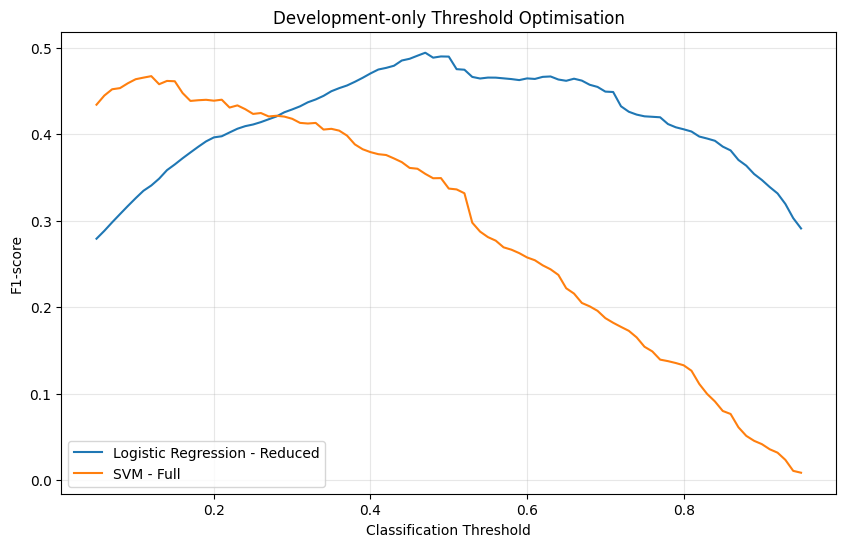

In [28]:
# Cell 27: Development threshold comparison

plt.figure(figsize=(10, 6))

for model_name in development_threshold_df["Model"].unique():

    subset = development_threshold_df[
        development_threshold_df["Model"] == model_name
    ]

    plt.plot(
        subset["Threshold"],
        subset["F1_Score"],
        label=model_name
    )

plt.xlabel("Classification Threshold")
plt.ylabel("F1-score")
plt.title("Development-only Threshold Optimisation")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [29]:
# Cell 28: Train selected model on development data

from sklearn.base import clone

selected_model_name = "Logistic Regression - Reduced"
selected_threshold = 0.47

final_model = clone(
    development_models[selected_model_name]
)

# Use only the selected features
X_train_final = X_dev[reduced_features].copy()
X_holdout_final = X_test[reduced_features].copy()

# Train only on development observations
final_model.fit(X_train_final, y_dev)

print("Selected model:", selected_model_name)
print("Selected threshold:", selected_threshold)
print("Training observations:", len(X_train_final))
print("Holdout observations:", len(X_holdout_final))
print("\nModel training completed successfully!")

Selected model: Logistic Regression - Reduced
Selected threshold: 0.47
Training observations: 6241
Holdout observations: 2740

Model training completed successfully!


In [30]:
# Cell 29: Predict on holdout wildfire groups

holdout_probabilities = final_model.predict_proba(
    X_holdout_final
)[:, 1]

holdout_predictions = (
    holdout_probabilities >= selected_threshold
).astype(int)

print("Holdout predictions generated!")

print("Predicted positive observations:",
      holdout_predictions.sum())

print("Predicted negative observations:",
      (holdout_predictions == 0).sum())

print("Actual positive observations:",
      y_test.sum())

print("Actual negative observations:",
      (y_test == 0).sum())

Holdout predictions generated!
Predicted positive observations: 473
Predicted negative observations: 2267
Actual positive observations: 218
Actual negative observations: 2522


In [31]:
# Cell 30: Holdout evaluation

holdout_metrics = {
    "Accuracy": accuracy_score(y_test, holdout_predictions),
    "Precision": precision_score(
        y_test, holdout_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, holdout_predictions, zero_division=0
    ),
    "F1_Score": f1_score(
        y_test, holdout_predictions, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(
        y_test, holdout_probabilities
    ),
    "PR_AUC": average_precision_score(
        y_test, holdout_probabilities
    )
}

holdout_results_df = pd.DataFrame(
    [holdout_metrics]
)

print("Post-selection Wildfire-Group Holdout Results:")
display(holdout_results_df.round(4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, holdout_predictions))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        holdout_predictions,
        target_names=[
            "No Debris Flow (0)",
            "Debris Flow (1)"
        ],
        digits=4
    )
)

Post-selection Wildfire-Group Holdout Results:


,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
0,0.8697,0.3531,0.7661,0.4834,0.91,0.6228



Confusion Matrix:
[[2216  306]
 [  51  167]]

Classification Report:
                    precision    recall  f1-score   support

No Debris Flow (0)     0.9775    0.8787    0.9255      2522
   Debris Flow (1)     0.3531    0.7661    0.4834       218

          accuracy                         0.8697      2740
         macro avg     0.6653    0.8224    0.7044      2740
      weighted avg     0.9278    0.8697    0.8903      2740



In [32]:
# Cell 31: Wildfire-wise Holdout Performance

holdout_analysis = pd.DataFrame({
    "FireName": X_test["FireName"].values,
    "Actual": y_test.values,
    "Predicted": holdout_predictions,
    "Probability": holdout_probabilities
})

fire_performance = []

for fire_name, fire_df in holdout_analysis.groupby("FireName"):

    tn, fp, fn, tp = confusion_matrix(
        fire_df["Actual"],
        fire_df["Predicted"],
        labels=[0, 1]
    ).ravel()

    fire_performance.append({
        "FireName": fire_name,
        "Total_Observations": len(fire_df),
        "Actual_Positives": int(fire_df["Actual"].sum()),
        "Predicted_Positives": int(fire_df["Predicted"].sum()),
        "True_Positives": tp,
        "False_Positives": fp,
        "False_Negatives": fn,
        "Precision": precision_score(
            fire_df["Actual"],
            fire_df["Predicted"],
            zero_division=0
        ),
        "Recall": recall_score(
            fire_df["Actual"],
            fire_df["Predicted"],
            zero_division=0
        )
    })

fire_performance_df = pd.DataFrame(fire_performance)

display(
    fire_performance_df.round(4).sort_values(
        by="Recall",
        ascending=False
    )
)

print("\nNumber of holdout wildfire groups:",
      len(fire_performance_df))

,FireName,Total_Observations,Actual_Positives,Predicted_Positives,True_Positives,False_Positives,False_Negatives,Precision,Recall
0,Bear,1,1,1,1,0,0,1.0000,1.0000
10,Woodbury,26,22,26,22,4,0,0.8462,1.0000
9,Schultz,109,30,61,30,31,0,0.4918,1.0000
7,Pipeline,1,1,1,1,0,0,1.0000,1.0000
5,Grand Prix - Old,78,60,65,53,12,7,0.8154,0.8833
8,River,8,7,7,6,1,1,0.8571,0.8571
6,Grizzly Creek,2450,50,282,34,248,16,0.1206,0.6800
4,El Dorado,24,15,15,9,6,6,0.6000,0.6000
1,Bond,9,9,5,5,0,4,1.0000,0.5556
2,Boot,3,2,1,1,0,1,1.0000,0.5000



Number of holdout wildfire groups: 11


In [33]:
# Cell 32: Logistic Regression Feature Importance

feature_names = reduced_features

coefficients = final_model.named_steps["model"].coef_[0]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Importance": np.abs(coefficients),
    "Odds_Ratio": np.exp(coefficients)
})

importance_df = importance_df.sort_values(
    by="Absolute_Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df.round(4))

,Feature,Coefficient,Absolute_Importance,Odds_Ratio
0,PeakI60,1.0074,1.0074,2.7386
1,HM23,0.6908,0.6908,1.9953
2,YearAfterFire,-0.5604,0.5604,0.5710
3,RainfallRatio60,0.5311,0.5311,1.7007
4,StormAccumulation,0.3625,0.3625,1.4369
5,UpstreamArea,0.3393,0.3393,1.4040
6,DaysSinceFire,0.2734,0.2734,1.3144
7,dNBR/1000,-0.2424,0.2424,0.7848
8,StormDuration,-0.1645,0.1645,0.8483
9,KF,0.0201,0.0201,1.0203


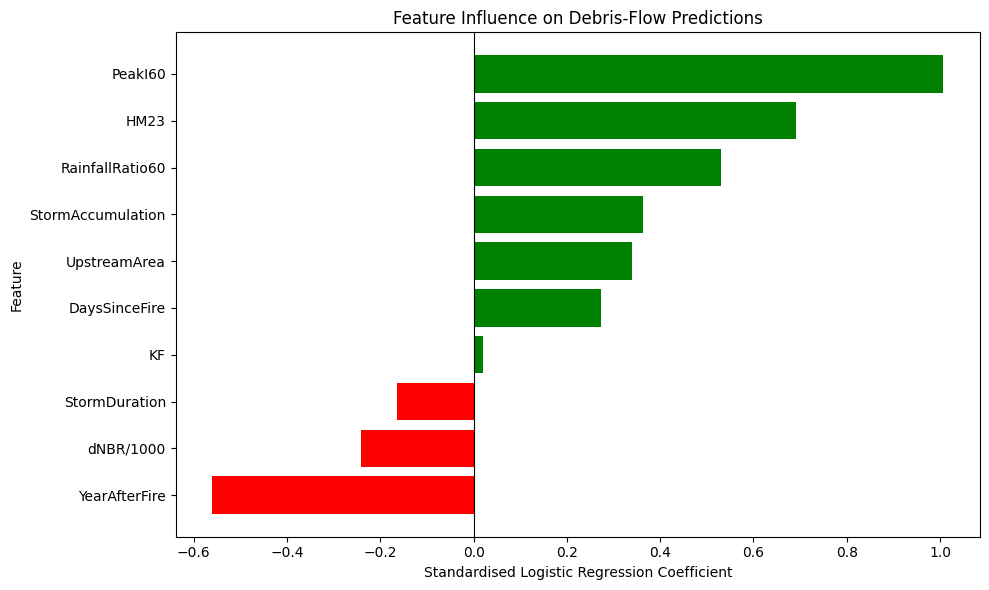

In [34]:
# Cell 33: Feature Importance Plot

plt.figure(figsize=(10, 6))

plot_df = importance_df.sort_values(
    by="Coefficient"
)

colors = [
    "red" if value < 0 else "green"
    for value in plot_df["Coefficient"]
]

plt.barh(
    plot_df["Feature"],
    plot_df["Coefficient"],
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("Standardised Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Feature Influence on Debris-Flow Predictions")

plt.tight_layout()
plt.show()

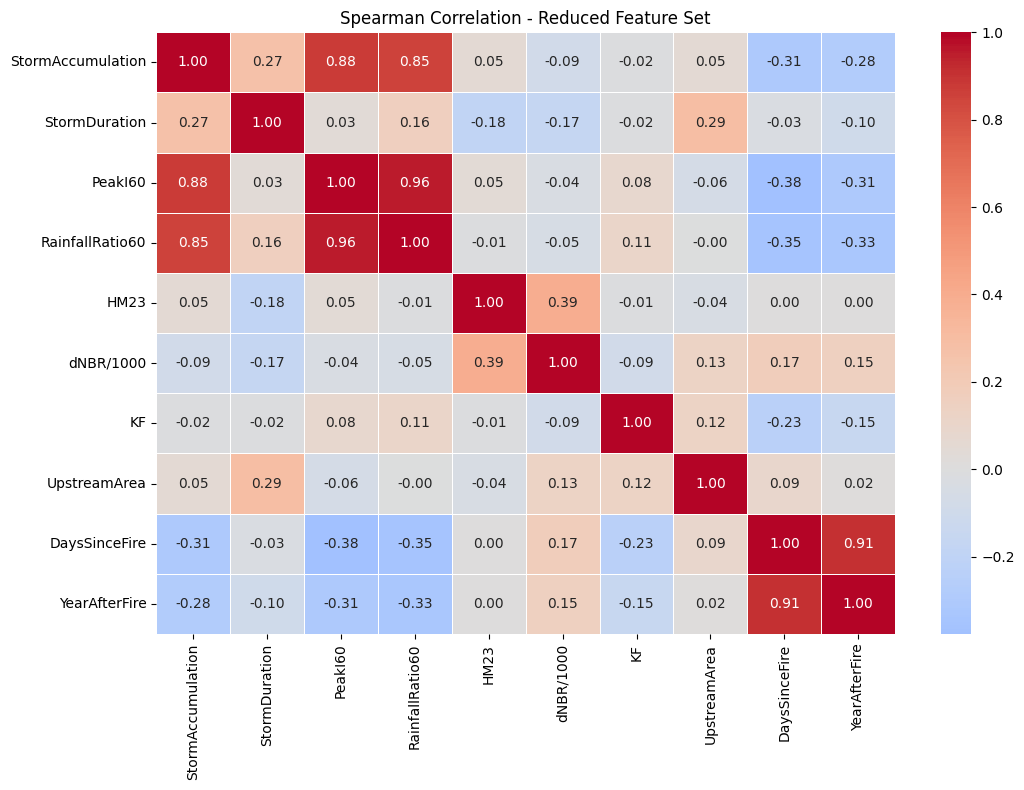

In [35]:
# Cell 34: Correlation among selected model features

correlation_matrix = df[reduced_features].corr(
    method="spearman"
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Spearman Correlation - Reduced Feature Set")
plt.tight_layout()
plt.show()

In [36]:
# Cell 35: Identify highly correlated feature pairs

correlation_pairs = []

for i in range(len(reduced_features)):
    for j in range(i + 1, len(reduced_features)):

        feature_1 = reduced_features[i]
        feature_2 = reduced_features[j]

        correlation = correlation_matrix.loc[
            feature_1, feature_2
        ]

        if abs(correlation) >= 0.70:

            correlation_pairs.append({
                "Feature_1": feature_1,
                "Feature_2": feature_2,
                "Correlation": correlation
            })

correlation_pairs_df = pd.DataFrame(
    correlation_pairs
)

if len(correlation_pairs_df) > 0:
    display(
        correlation_pairs_df.sort_values(
            by="Correlation",
            key=lambda x: x.abs(),
            ascending=False
        ).round(4)
    )
else:
    print("No feature pairs with absolute correlation >= 0.70")

,Feature_1,Feature_2,Correlation
2,PeakI60,RainfallRatio60,0.9560
3,DaysSinceFire,YearAfterFire,0.9085
0,StormAccumulation,PeakI60,0.8795
1,StormAccumulation,RainfallRatio60,0.8512


In [37]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 5.1 MB/s  0:00:00

   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------------------------------------- 0/4 [tqdm]
   ---------- ----------------------------- 1/4 [slicer]
   -------------------- ------------------- 2/4 [cloudpickle]
   ------------------------------ --------- 3/4 [shap]
   ------------------------------ --------- 3/4 [shap]
   ------------------------------ --------- 3/4 [shap]
   ------------------------------ --------- 3/4 [shap]
   ------------------------------ --------- 3/4 [shap]
   ------------------------------ --------- 3/4 [shap]
   ------------------------------ --------- 3/4 [shap]
   ------------------------------ --------- 3/4 [shap]
   --------------


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\VIKASH\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [38]:
# Cell 36: Import SHAP

try:
    import shap
    print("SHAP imported successfully!")
    print("SHAP version:", shap.__version__)

except ImportError:
    print("SHAP is not installed.")
    print("Run this in a separate cell: %pip install shap")

SHAP imported successfully!
SHAP version: 0.54.1


In [39]:
# Cell 37: Prepare transformed data for SHAP

# Extract fitted preprocessing steps
imputer = final_model.named_steps["imputer"]
scaler = final_model.named_steps["scaler"]
logistic_model = final_model.named_steps["model"]

# Select background observations from development data
background_data = X_train_final.sample(
    n=min(200, len(X_train_final)),
    random_state=42
)

# Apply the fitted preprocessing transformations
background_imputed = imputer.transform(background_data)

background_scaled = scaler.transform(
    background_imputed
)

# Transform holdout observations
holdout_imputed = imputer.transform(
    X_holdout_final
)

holdout_scaled = scaler.transform(
    holdout_imputed
)

print("Background data shape:", background_scaled.shape)
print("Holdout data shape:", holdout_scaled.shape)

print("\nSHAP data prepared successfully!")

Background data shape: (200, 10)
Holdout data shape: (2740, 10)

SHAP data prepared successfully!


In [40]:
# Cell 38: Calculate SHAP values for Logistic Regression

explainer = shap.LinearExplainer(
    logistic_model,
    background_scaled,
    feature_perturbation="interventional"
)

shap_values = explainer.shap_values(
    holdout_scaled
)

# Handle different SHAP output formats
if isinstance(shap_values, list):
    shap_values = shap_values[-1]

shap_values = np.asarray(shap_values)

if shap_values.ndim == 3:
    if shap_values.shape[0] == len(holdout_scaled):
        shap_values = shap_values[:, :, -1]
    else:
        shap_values = shap_values[-1]

print("SHAP values generated successfully!")
print("SHAP values shape:", shap_values.shape)

C:\Users\VIKASH\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\shap\explainers\_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)
Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


SHAP values generated successfully!
SHAP values shape: (2740, 10)


In [41]:
# Cell 39: Global SHAP Feature Importance

mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": reduced_features,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_importance_df = shap_importance_df.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

display(shap_importance_df.round(4))

,Feature,Mean_Absolute_SHAP
0,PeakI60,0.6215
1,UpstreamArea,0.5647
2,YearAfterFire,0.5369
3,HM23,0.4842
4,StormDuration,0.4240
5,RainfallRatio60,0.3679
6,DaysSinceFire,0.2656
7,dNBR/1000,0.1601
8,StormAccumulation,0.1177
9,KF,0.0164


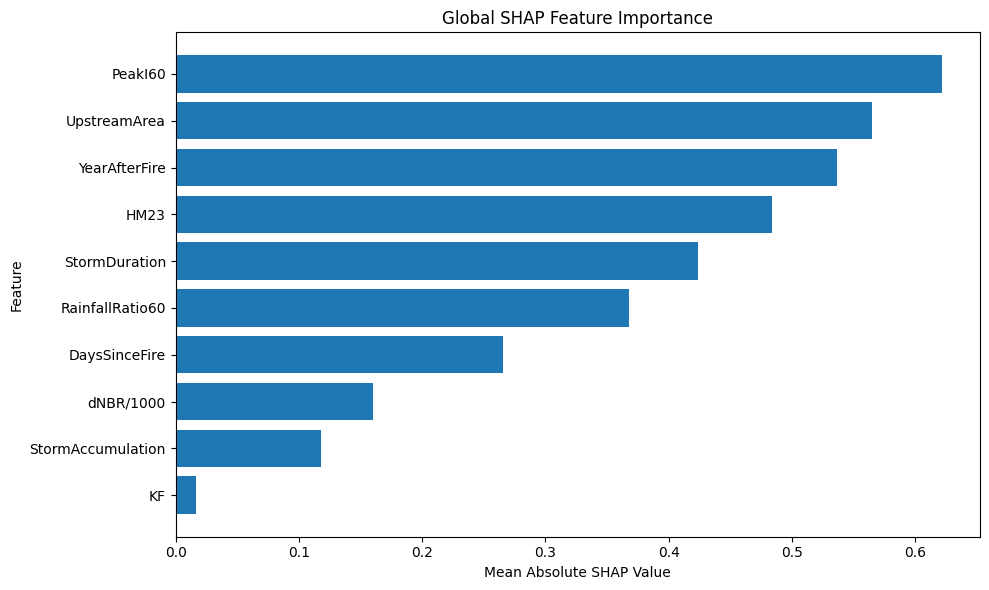

In [42]:
# Cell 40: Global SHAP Importance Bar Chart

plt.figure(figsize=(10, 6))

plot_df = shap_importance_df.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=True
)

plt.barh(
    plot_df["Feature"],
    plot_df["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Global SHAP Feature Importance")

plt.tight_layout()
plt.show()

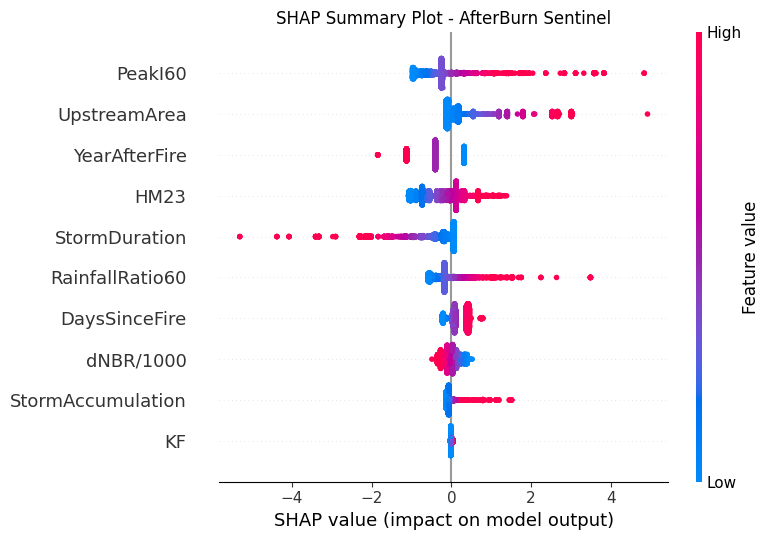

In [43]:
# Cell 41: Prepare original feature values for SHAP plotting

holdout_display_df = pd.DataFrame(
    holdout_imputed,
    columns=reduced_features,
    index=X_holdout_final.index
)

# SHAP Summary / Beeswarm Plot
shap.summary_plot(
    shap_values,
    features=holdout_display_df,
    feature_names=reduced_features,
    max_display=10,
    show=False
)

plt.title("SHAP Summary Plot - AfterBurn Sentinel")
plt.tight_layout()
plt.show()

In [44]:
# Cell 42: Select individual observations for SHAP explanation

# Find correctly detected positive observations
tp_positions = np.where(
    (y_test.to_numpy() == 1) &
    (holdout_predictions == 1)
)[0]

# Find missed positive observations
fn_positions = np.where(
    (y_test.to_numpy() == 1) &
    (holdout_predictions == 0)
)[0]

# Select the highest-probability true positive
tp_position = tp_positions[
    np.argmax(holdout_probabilities[tp_positions])
]

# Select the lowest-probability false negative
fn_position = fn_positions[
    np.argmin(holdout_probabilities[fn_positions])
]

print("TRUE POSITIVE OBSERVATION")
print("-------------------------")
print("Fire:", X_test.iloc[tp_position]["FireName"])
print("Actual response:", y_test.iloc[tp_position])
print("Predicted response:", holdout_predictions[tp_position])
print("Predicted probability:", round(
    holdout_probabilities[tp_position], 4
))

print("\nFALSE NEGATIVE OBSERVATION")
print("--------------------------")
print("Fire:", X_test.iloc[fn_position]["FireName"])
print("Actual response:", y_test.iloc[fn_position])
print("Predicted response:", holdout_predictions[fn_position])
print("Predicted probability:", round(
    holdout_probabilities[fn_position], 4
))

TRUE POSITIVE OBSERVATION
-------------------------
Fire: Grizzly Creek
Actual response: 1
Predicted response: 1
Predicted probability: 0.9995

FALSE NEGATIVE OBSERVATION
--------------------------
Fire: Cameron Peak
Actual response: 1
Predicted response: 0
Predicted probability: 0.0592


In [45]:
# Cell 43: Create SHAP explanations for individual observations

base_value = float(
    np.asarray(explainer.expected_value).reshape(-1)[-1]
)

tp_explanation = shap.Explanation(
    values=shap_values[tp_position],
    base_values=base_value,
    data=holdout_display_df.iloc[tp_position].to_numpy(),
    feature_names=reduced_features
)

fn_explanation = shap.Explanation(
    values=shap_values[fn_position],
    base_values=base_value,
    data=holdout_display_df.iloc[fn_position].to_numpy(),
    feature_names=reduced_features
)

print("Individual SHAP explanations prepared successfully!")

Individual SHAP explanations prepared successfully!


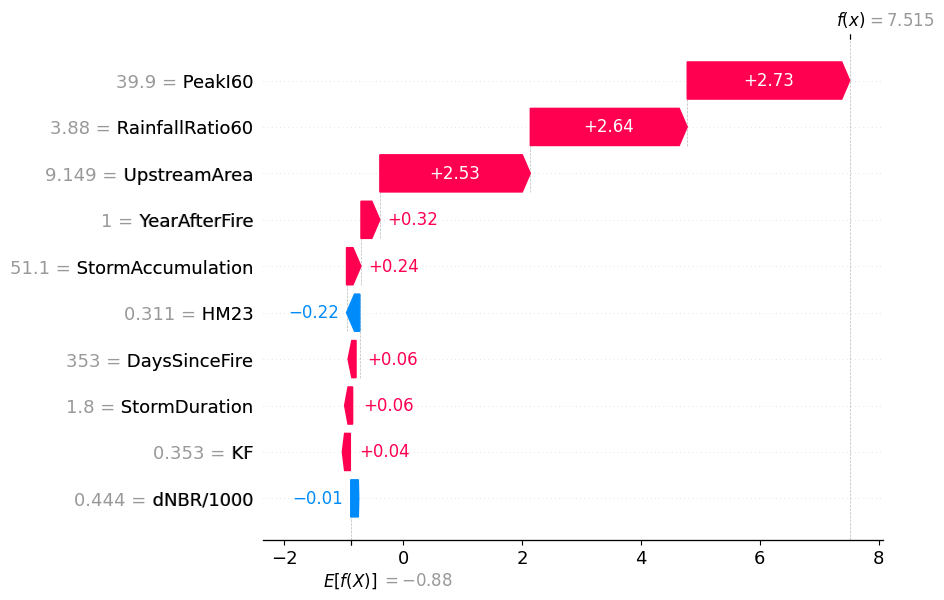

In [46]:
# Cell 44: Explain correctly detected debris-flow observation

shap.plots.waterfall(
    tp_explanation,
    max_display=10
)

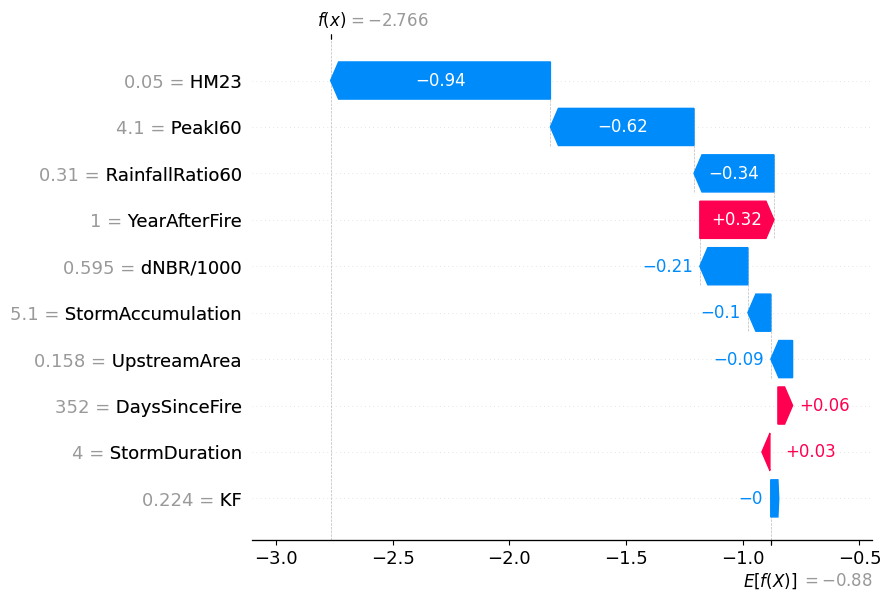

In [47]:
# Cell 45: Explain missed debris-flow observation

shap.plots.waterfall(
    fn_explanation,
    max_display=10
)

In [48]:
# Cell 46: Individual SHAP Explanation Report

selected_cases = {
    "True Positive": tp_position,
    "False Negative": fn_position
}

case_summary = []
case_contributions = []

for case_name, position in selected_cases.items():

    observation = X_test.iloc[position]

    case_summary.append({
        "Case": case_name,
        "FireName": observation["FireName"],
        "ObservationID": observation["UniqueObservationID"],
        "Actual_Response": int(y_test.iloc[position]),
        "Predicted_Response": int(holdout_predictions[position]),
        "Predicted_Probability": holdout_probabilities[position],
        "Classification_Threshold": selected_threshold
    })

    contribution_df = pd.DataFrame({
        "Case": case_name,
        "Feature": reduced_features,
        "Observed_Value": holdout_display_df.iloc[position].values,
        "SHAP_Contribution": shap_values[position]
    })

    case_contributions.append(contribution_df)

case_summary_df = pd.DataFrame(case_summary)

case_contributions_df = pd.concat(
    case_contributions,
    ignore_index=True
)

print("INDIVIDUAL OBSERVATION SUMMARY")
display(case_summary_df.round(4))

print("\nINDIVIDUAL SHAP CONTRIBUTIONS")
display(
    case_contributions_df.sort_values(
        ["Case", "SHAP_Contribution"],
        key=lambda x: x.abs() if x.name == "SHAP_Contribution" else x,
        ascending=[True, False]
    ).round(4)
)

INDIVIDUAL OBSERVATION SUMMARY


,Case,FireName,ObservationID,Actual_Response,Predicted_Response,Predicted_Probability,Classification_Threshold
0,True Positive,Grizzly Creek,GrizzlyCreek_2020_1001,1,1,0.9995,0.47
1,False Negative,Cameron Peak,CameronPeak_2020_0026,1,0,0.0592,0.47



INDIVIDUAL SHAP CONTRIBUTIONS


,Case,Feature,Observed_Value,SHAP_Contribution
14,False Negative,HM23,0.0500,-0.9420
12,False Negative,PeakI60,4.1000,-0.6152
13,False Negative,RainfallRatio60,0.3100,-0.3428
19,False Negative,YearAfterFire,1.0000,0.3179
15,False Negative,dNBR/1000,0.5948,-0.2059
10,False Negative,StormAccumulation,5.1000,-0.0985
17,False Negative,UpstreamArea,0.1582,-0.0932
18,False Negative,DaysSinceFire,352.0000,0.0629
11,False Negative,StormDuration,4.0000,0.0343
16,False Negative,KF,0.2236,-0.0036


In [49]:
# Verify holdout variables

required_variables = [
    "X_test",
    "y_test",
    "holdout_predictions",
    "holdout_probabilities",
    "selected_threshold"
]

for variable in required_variables:
    print(
        variable,
        "Available" if variable in globals() else "Missing"
    )

X_test Available
y_test Available
holdout_predictions Available
holdout_probabilities Available
selected_threshold Available


In [50]:
# Cell 47: Export holdout predictions for geospatial analysis

import os

# Select geographic and identification columns
geo_columns = [
    "FireName",
    "FireState",
    "UniqueObservationID",
    "ObservationLatitude",
    "ObservationLongitude"
]

geo_results = X_test[geo_columns].reset_index(drop=True).copy()

# Add actual and predicted responses
geo_results["Actual_Response"] = y_test.to_numpy()
geo_results["Predicted_Response"] = holdout_predictions
geo_results["Predicted_Probability"] = holdout_probabilities

# Store the selected classification threshold
geo_results["Threshold"] = selected_threshold

# Add model name
geo_results["Model"] = "Logistic Regression - Reduced"

# Categorise every prediction
conditions = [
    (geo_results["Actual_Response"] == 1) &
    (geo_results["Predicted_Response"] == 1),

    (geo_results["Actual_Response"] == 0) &
    (geo_results["Predicted_Response"] == 0),

    (geo_results["Actual_Response"] == 0) &
    (geo_results["Predicted_Response"] == 1),

    (geo_results["Actual_Response"] == 1) &
    (geo_results["Predicted_Response"] == 0)
]

choices = [
    "True Positive",
    "True Negative",
    "False Positive",
    "False Negative"
]

geo_results["Error_Type"] = np.select(
    conditions,
    choices,
    default="Unknown"
)

# Validate geographic coordinates
geo_results["ObservationLatitude"] = pd.to_numeric(
    geo_results["ObservationLatitude"],
    errors="coerce"
)

geo_results["ObservationLongitude"] = pd.to_numeric(
    geo_results["ObservationLongitude"],
    errors="coerce"
)

valid_coordinates = (
    geo_results["ObservationLatitude"].between(-90, 90) &
    geo_results["ObservationLongitude"].between(-180, 180)
)

print("Total observations:", len(geo_results))
print("Valid geographic coordinates:", valid_coordinates.sum())
print("Invalid or missing coordinates:", (~valid_coordinates).sum())

print("\nPrediction category counts:")
display(geo_results["Error_Type"].value_counts())

# Save the mapping dataset
output_path = "../data/processed/holdout_geospatial_results.csv"

geo_results.to_csv(output_path, index=False)

print("\nGeospatial dataset saved successfully!")
print("Saved at:", output_path)

Total observations: 2740
Valid geographic coordinates: 2740
Invalid or missing coordinates: 0

Prediction category counts:


Error_Type
True Negative     2216
False Positive     306
True Positive      167
False Negative      51
Name: count, dtype: int64


Geospatial dataset saved successfully!
Saved at: ../data/processed/holdout_geospatial_results.csv


In [51]:
# Cell 2: Geospatial Data Validation

# Convert coordinates to numeric values
geo_results["ObservationLatitude"] = pd.to_numeric(
    geo_results["ObservationLatitude"],
    errors="coerce"
)

geo_results["ObservationLongitude"] = pd.to_numeric(
    geo_results["ObservationLongitude"],
    errors="coerce"
)

# Check coordinate validity
valid_coordinates = (
    geo_results["ObservationLatitude"].between(-90, 90) &
    geo_results["ObservationLongitude"].between(-180, 180)
)

print("Total observations:", len(geo_results))
print("Valid coordinates:", valid_coordinates.sum())
print("Invalid coordinates:", (~valid_coordinates).sum())

# Prediction category distribution
print("\nPrediction Category Distribution:")
display(
    geo_results["Error_Type"].value_counts().to_frame("Count")
)

# Wildfire and state distribution
print("\nUnique wildfire groups:",
      geo_results["FireName"].nunique())

print("\nObservations by state:")
display(
    geo_results["FireState"].value_counts().to_frame("Observations")
)

# Geographic extent
print("\nGeographic extent:")
print("Minimum latitude:",
      geo_results["ObservationLatitude"].min())
print("Maximum latitude:",
      geo_results["ObservationLatitude"].max())
print("Minimum longitude:",
      geo_results["ObservationLongitude"].min())
print("Maximum longitude:",
      geo_results["ObservationLongitude"].max())

Total observations: 2740
Valid coordinates: 2740
Invalid coordinates: 0

Prediction Category Distribution:


,Count
Error_Type,
True Negative,2216
False Positive,306
True Positive,167
False Negative,51



Unique wildfire groups: 11

Observations by state:


,Observations
FireState,
CO,2481
AZ,136
CA,122
UT,1



Geographic extent:
Minimum latitude: 33.528998
Maximum latitude: 40.7401849
Minimum longitude: -121.63517
Maximum longitude: -105.4180111


In [2]:
# Export final AfterBurn Sentinel model

import os
import json
import joblib
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# 1. Load cleaned dataset
df_export = pd.read_csv(
    "../data/processed/usgs_inventory_missing_cleaned.csv"
)

# 2. Define selected features
reduced_features = [
    "StormAccumulation",
    "StormDuration",
    "PeakI60",
    "RainfallRatio60",
    "HM23",
    "dNBR/1000",
    "KF",
    "UpstreamArea",
    "DaysSinceFire",
    "YearAfterFire"
]

y_export = df_export["Response"]
groups_export = df_export["FireName"]

# 3. Recreate the same wildfire-group split
holdout_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

train_idx, test_idx = next(
    holdout_cv.split(df_export, y_export, groups_export)
)

X_dev = df_export.iloc[train_idx][reduced_features]
y_dev = y_export.iloc[train_idx]

# 4. Recreate the selected Logistic Regression pipeline
final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    ))
])

# 5. Train using development data
final_model.fit(X_dev, y_dev)

# 6. Set development-selected threshold
selected_threshold = 0.47

# 7. Create models directory
os.makedirs("../models", exist_ok=True)

# 8. Save trained pipeline
joblib.dump(
    final_model,
    "../models/afterburn_logistic_regression.joblib"
)

# 9. Save model configuration
model_metadata = {
    "model_name": "Logistic Regression - Reduced Features",
    "threshold": selected_threshold,
    "features": reduced_features,
    "target": "Response",
    "positive_class": 1,
    "training_observations": len(X_dev),
    "training_wildfire_groups": groups_export.iloc[train_idx].nunique()
}

with open("../models/model_metadata.json", "w") as file:
    json.dump(model_metadata, file, indent=4)

print("Final model exported successfully!")
print("Training observations:", len(X_dev))
print("Training wildfire groups:",
      groups_export.iloc[train_idx].nunique())
print("Classification threshold:", selected_threshold)

print("\nSaved files:")
print("1. models/afterburn_logistic_regression.joblib")
print("2. models/model_metadata.json")

Final model exported successfully!
Training observations: 6241
Training wildfire groups: 69
Classification threshold: 0.47

Saved files:
1. models/afterburn_logistic_regression.joblib
2. models/model_metadata.json


In [3]:
# Verify exported model

import joblib
import json
import pandas as pd

model_path = "../models/afterburn_logistic_regression.joblib"
metadata_path = "../models/model_metadata.json"

# Load saved model
loaded_model = joblib.load(model_path)

# Load model configuration
with open(metadata_path, "r") as file:
    metadata = json.load(file)

# Create a sample using median feature values
df_reference = pd.read_csv(
    "../data/processed/usgs_inventory_missing_cleaned.csv"
)

sample_input = pd.DataFrame([
    df_reference[metadata["features"]].median().to_dict()
])

# Generate sample prediction
sample_probability = loaded_model.predict_proba(
    sample_input
)[0, 1]

sample_prediction = int(
    sample_probability >= metadata["threshold"]
)

print("Model loaded successfully!")
print("Model:", metadata["model_name"])
print("Features:", len(metadata["features"]))
print("Threshold:", metadata["threshold"])
print("Sample probability:", round(sample_probability, 4))
print("Sample prediction:", sample_prediction)

Model loaded successfully!
Model: Logistic Regression - Reduced Features
Features: 10
Threshold: 0.47
Sample probability: 0.2075
Sample prediction: 0
